In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Define the dictionary we want to use
aruco_dict = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_6X6_250)

# Generate a marker
marker_id = 42
marker_size = 200  # Size in pixels
marker_image = cv2.aruco.generateImageMarker(aruco_dict, marker_id, marker_size)

cv2.imwrite('marker_42.png', marker_image)
plt.imshow(marker_image, cmap='gray', interpolation='nearest')
plt.axis('off')  # Hide axes
plt.title(f'ArUco Marker {marker_id}')
plt.show()

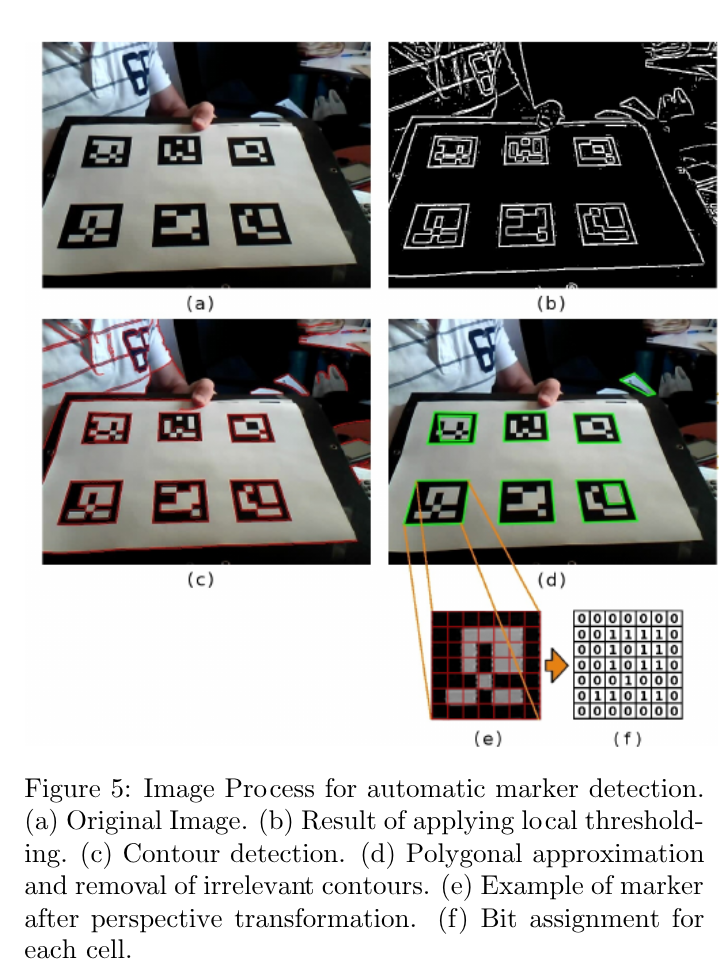

In [1]:
import cv2
import numpy as np
# code written with the help of gemini (but fully understood by me).
def main():
    # ==========================================
    # 1. PHYSICAL DIMENSIONS & CALIBRATION
    # ==========================================
    # Define the physical size of your printed marker in meters. 
    # Example: 10 cm = 0.10 meters. 
    # If this number is wrong, your Z-axis distance calculation will be completely wrong.
    MARKER_SIZE = 0.10 
    
    # Mathematical definition of the 3D marker corners relative to its own center (Z = 0)
    # Order: Top-Left, Top-Right, Bottom-Right, Bottom-Left
    marker_3d_points = np.array([
        [-MARKER_SIZE / 2,  MARKER_SIZE / 2, 0],
        [ MARKER_SIZE / 2,  MARKER_SIZE / 2, 0],
        [ MARKER_SIZE / 2, -MARKER_SIZE / 2, 0],
        [-MARKER_SIZE / 2, -MARKER_SIZE / 2, 0]
    ], dtype=np.float32)

    # Generic Camera Intrinsic Matrix (K) for a standard 720p webcam (1280x720)
    # WARNING: This is an approximation. For sub-millimeter tracking, you MUST run 
    # a checkerboard camera calibration script to get the true focal length of your specific lens.
    focal_length = 1000.0
    center_x = 640.0
    center_y = 360.0
    camera_matrix = np.array([
        [focal_length, 0.0, center_x],
        [0.0, focal_length, center_y],
        [0.0, 0.0, 1.0]
    ], dtype=np.float32)
    
    # Assuming zero lens distortion for the webcam placeholder
    dist_coeffs = np.zeros((5, 1), dtype=np.float32)

    # ==========================================
    # 2. ALGORITHM CONFIGURATION
    # ==========================================
    # Define the exact dictionary your printed marker belongs to
    aruco_dict = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_6X6_250)
    parameters = cv2.aruco.DetectorParameters()
    detector = cv2.aruco.ArucoDetector(aruco_dict, parameters)

    # ==========================================
    # 3. WEBCAM INITIALIZATION
    # ==========================================
    # '0' targets the default built-in laptop webcam. 
    # Change to '1' or '2' if you have external USB cameras plugged in.
    cap = cv2.VideoCapture(0)
    
    # Force the webcam to output a 1280x720 resolution
    cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
    cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)

    if not cap.isOpened():
        print("Error: Could not access the webcam.")
        return

    print("Webcam successfully opened. Press 'q' to quit the tracker.")

    # ==========================================
    # 4. THE REAL-TIME PROCESSING LOOP
    # ==========================================
    while True:
        # Capture a single frame from the live video feed
        ret, frame = cap.read()
        if not ret:
            print("Failed to grab frame. Exiting...")
            break
            
        # Convert the frame to grayscale for faster, light-invariant processing
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        # Execute the 2D detection pipeline
        corners, ids, rejected = detector.detectMarkers(gray)

        # Check if any markers were successfully decoded in this specific frame
        if ids is not None:
            
            # Draw the green 2D square outline and the ID number on the image
            cv2.aruco.drawDetectedMarkers(frame, corners, ids)

            # Iterate through every marker found in the frame
            for i in range(len(ids)):
                marker_id = ids[i][0]
                marker_2d_pixels = corners[i][0]

                # Execute 3D Pose Estimation (SolvePnP)
                success, rvec, tvec = cv2.solvePnP(
                    marker_3d_points, 
                    marker_2d_pixels, 
                    camera_matrix, 
                    dist_coeffs, 
                    flags=cv2.SOLVEPNP_IPPE_SQUARE
                )

                if success:
                    # Extract the absolute distance from the camera lens (Z-axis)
                    distance_meters = tvec[2][0]
                    
                    # Display the distance as text directly on the live video feed
                    text = f"ID: {marker_id} | Dist: {distance_meters:.2f}m"
                    
                    # Place the text slightly above the top-left corner of the detected marker
                    text_x = int(marker_2d_pixels[0][0])
                    text_y = int(marker_2d_pixels[0][1]) - 15
                    cv2.putText(frame, text, (text_x, text_y), 
                                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

                    # Visually draw the 3D coordinate axes protruding from the center of the marker
                    # The 'length=0.05' parameter dictates the visual length of the drawn lines in meters (5 cm)
                    cv2.drawFrameAxes(frame, camera_matrix, dist_coeffs, rvec, tvec, length=0.05)

        # Display the processed frame to the user
        cv2.imshow("Live ArUco 3D Tracker", frame)

        # Wait 1 millisecond for a keyboard interrupt. If 'q' is pressed, break the loop.
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    # ==========================================
    # 5. SAFE SHUTDOWN
    # ==========================================
    # Release the hardware lock on the webcam and destroy all GUI windows
    cap.release()
    cv2.destroyAllWindows()

if __name__ == "__main__":
    main()

ModuleNotFoundError: No module named 'cv2'